# Final Top-K ablation — AgriCLIP → SAM2 (746 non-empty VegAnn validation images)

This notebook **reuses the original pipeline functions and checkpoints** from `AutoBox_vs_AgriCLIP_33.ipynb`. It evaluates K = 4, 6, 8, 10, 12, 14, 16, 24, 32, 49 with identical validation images, decoder, threshold, and prompt method. **No results are fabricated or scaled from the 755-image table.**

The original uploaded notebook references `get_agriclip_localization` but does not define it; this notebook supplies that function using its existing DINO→aligner→vegetation-score operations. Inspect the K=32 sanity check before using the results in the thesis.

In [1]:
# ============================================================
# CELL 1 — IMPORTS AND ENVIRONMENT
# ============================================================

import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import transforms

from datasets import load_dataset

print("=" * 70)
print("AGRICLIP + SAM2 PROMPT STRATEGY NOTEBOOK")
print("=" * 70)

print("PyTorch:", torch.__version__)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 70)

AGRICLIP + SAM2 PROMPT STRATEGY NOTEBOOK
PyTorch: 2.12.0+cu130
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [2]:
# ============================================================
# CELL 2 — PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

AGRICLIP_ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

# ------------------------------------------------------------
# DINO
# ------------------------------------------------------------

DINO_CANDIDATES = [
    PROJECT_ROOT
    / "agriclip_Zahra"
    / "weights"
    / "DINO-PT.pth",

    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
    / "Weights"
    / "DINO-PT.pth",

    PROJECT_ROOT
    / "DINO-PT.pth"
]

DINO_PATH = None

for candidate in DINO_CANDIDATES:
    if candidate.exists():
        DINO_PATH = candidate
        break

# ------------------------------------------------------------
# AgriCLIP aligner
# ------------------------------------------------------------

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

# ------------------------------------------------------------
# Original non-augmented fine-tuned SAM2
# ------------------------------------------------------------

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

MODEL_NAME = (
    "facebook/sam2.1-hiera-tiny"
)

print("=" * 70)
print("PATH CHECK")
print("=" * 70)

print("Project:")
print(PROJECT_ROOT)

print("\nAgriCLIP:")
print(AGRICLIP_ROOT)

print("\nDINO:")
print(DINO_PATH)

print("\nAligner:")
print(ALIGNER_PATH)

print("\nSAM2:")
print(SAM2_CHECKPOINT)

print("\nSAM2 exists:",
      SAM2_CHECKPOINT.exists())

print("Aligner exists:",
      ALIGNER_PATH.exists())

print("DINO exists:",
      DINO_PATH is not None and DINO_PATH.exists())

if DINO_PATH is None:
    raise FileNotFoundError(
        "DINO-PT.pth could not be found."
    )

assert ALIGNER_PATH.exists()
assert SAM2_CHECKPOINT.exists()

print("\n✓ All required weight files found")

PATH CHECK
Project:
/home/zahranadeem/thesis

AgriCLIP:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP

DINO:
/home/zahranadeem/thesis/agriclip_Zahra/weights/DINO-PT.pth

Aligner:
/home/zahranadeem/thesis/vegann_aligner.pth

SAM2:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt

SAM2 exists: True
Aligner exists: True
DINO exists: True

✓ All required weight files found


In [3]:
# ============================================================
# CELL 3 — AGRICLIP PYTHON PATH
# ============================================================

if str(AGRICLIP_ALIGNMENT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(AGRICLIP_ALIGNMENT_DIR)
    )

print("=" * 70)
print("AGRICLIP MODULE PATH")
print("=" * 70)

print(
    AGRICLIP_ALIGNMENT_DIR
)

print(
    "\n✓ AgriCLIP alignment directory added to sys.path"
)

AGRICLIP MODULE PATH
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment

✓ AgriCLIP alignment directory added to sys.path


In [4]:
# ============================================================
# CELL 4 — IMPORT TEXTTOCONCEPT
# ============================================================

from TextToConcept import (
    TextToConcept,
    ClipZeroShot
)

print("=" * 70)
print("TEXTTOCONCEPT")
print("=" * 70)

print(
    "TextToConcept:",
    TextToConcept
)

print(
    "ClipZeroShot:",
    ClipZeroShot
)

print("=" * 70)

TEXTTOCONCEPT
TextToConcept: <class 'TextToConcept.TextToConcept'>
ClipZeroShot: <class 'TextToConcept.ClipZeroShot'>


In [5]:
# ============================================================
# CELL 5 — LOAD VEGANN
# ============================================================

print("=" * 70)
print("LOADING VEGANN")
print("=" * 70)

vegann = load_dataset(
    "simonMadec/VegAnn"
)

print(vegann)

print(
    "\nOriginal dataset size:",
    len(vegann["train"])
)

LOADING VEGANN
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})

Original dataset size: 3775


In [6]:
# ============================================================
# CELL 6 — CREATE EXACT VEGANN TRAIN / VALIDATION SPLIT
# ============================================================

vegann_split = (
    vegann["train"]
    .train_test_split(
        test_size=0.20,
        seed=42
    )
)

train_hf = (
    vegann_split["train"]
)

val_hf = (
    vegann_split["test"]
)

print("=" * 70)
print("VEGANN SPLIT")
print("=" * 70)

print(
    "Training:",
    len(train_hf)
)

print(
    "Validation:",
    len(val_hf)
)

assert len(val_hf) == 755

print(
    "\n✓ Validation split = 755 images"
)

VEGANN SPLIT
Training: 3020
Validation: 755

✓ Validation split = 755 images


In [7]:
# ============================================================
# CELL 7 — VEGANN IMAGE / MASK KEYS
# ============================================================

print("=" * 70)
print("VEGANN COLUMNS")
print("=" * 70)

print(
    "Columns:",
    train_hf.column_names
)

# VegAnn normally uses image/mask.
# Detect automatically so the notebook does not depend
# on a stale variable from another notebook.

IMAGE_KEY = None
MASK_KEY = None

for key in [
    "image",
    "images",
    "img"
]:

    if key in train_hf.column_names:

        IMAGE_KEY = key
        break


for key in [
    "mask",
    "masks",
    "label",
    "labels",
    "segmentation",
    "annotation"
]:

    if key in train_hf.column_names:

        MASK_KEY = key
        break


print(
    "\nIMAGE_KEY:",
    IMAGE_KEY
)

print(
    "MASK_KEY:",
    MASK_KEY
)

if IMAGE_KEY is None:
    raise RuntimeError(
        "Could not find VegAnn image column."
    )

if MASK_KEY is None:
    raise RuntimeError(
        "Could not find VegAnn mask column."
    )

print(
    "\n✓ Dataset keys detected"
)

VEGANN COLUMNS
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']

IMAGE_KEY: image
MASK_KEY: mask

✓ Dataset keys detected


In [8]:
# ============================================================
# CELL 8 — IMAGE + MASK HELPERS
# ============================================================

def get_image(
    index,
    split=val_hf
):
    """
    Return a VegAnn image as RGB PIL.Image.
    """

    image = split[index][IMAGE_KEY]

    if isinstance(
        image,
        Image.Image
    ):

        return image.convert("RGB")

    image = np.asarray(
        image
    )

    return Image.fromarray(
        image
    ).convert("RGB")


def get_mask(
    index,
    split=val_hf
):
    """
    Return VegAnn vegetation mask as uint8 binary array.
    """

    mask = split[index][MASK_KEY]

    if isinstance(
        mask,
        Image.Image
    ):

        mask = np.asarray(mask)

    elif torch.is_tensor(mask):

        mask = (
            mask.detach()
            .cpu()
            .numpy()
        )

    else:

        mask = np.asarray(mask)

    if mask.ndim == 3:

        mask = mask[..., 0]

    return (
        mask > 0
    ).astype(np.uint8)


# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

test_image = get_image(0)
test_mask = get_mask(0)

print("=" * 70)
print("IMAGE / MASK TEST")
print("=" * 70)

print(
    "Image type:",
    type(test_image)
)

print(
    "Image size:",
    test_image.size
)

print(
    "Mask shape:",
    test_mask.shape
)

print(
    "Foreground:",
    int(test_mask.sum())
)

print("=" * 70)

IMAGE / MASK TEST
Image type: <class 'PIL.Image.Image'>
Image size: (512, 512)
Mask shape: (512, 512)
Foreground: 208628


In [9]:
# ============================================================
# CELL 9 — LOAD DINO RESNET-50
# ============================================================

print("=" * 70)
print("LOADING DINO RESNET-50")
print("=" * 70)

dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

print(
    "DINO model:",
    type(dino_model)
)

print(
    "\nLoading checkpoint:",
    DINO_PATH
)

dino_state_dict = torch.load(
    DINO_PATH,
    map_location="cpu",
    weights_only=True
)

load_result = dino_model.load_state_dict(
    dino_state_dict,
    strict=True
)

print(
    "\nDINO load result:",
    load_result
)

dino_model = (
    dino_model
    .to(device)
)

dino_model.eval()

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print(
    "\n✓ DINO loaded and frozen"
)

print(
    "Layer4:",
    dino_model.layer4
)

print("=" * 70)

LOADING DINO RESNET-50


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO model: <class 'torchvision.models.resnet.ResNet'>

Loading checkpoint: /home/zahranadeem/thesis/agriclip_Zahra/weights/DINO-PT.pth

DINO load result: <All keys matched successfully>

✓ DINO loaded and frozen
Layer4: Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(1024, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(1024, 2048, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (1): BatchNorm2d(2048, eps=1e-05, momentum=0.

In [10]:
# ============================================================
# CELL 10 — DINO PREPROCESSING
# ============================================================

dino_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

print("=" * 70)
print("DINO TRANSFORM")
print("=" * 70)

print(dino_transform)

print("=" * 70)

DINO TRANSFORM
Compose(
    Resize(size=224, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [11]:
# ============================================================
# CELL 11 — DINO LAYER4 HOOK
# ============================================================

captured_feature_map = None


def capture_layer4_output(
    module,
    inputs,
    output
):

    global captured_feature_map

    captured_feature_map = (
        output.detach()
    )


hook_handle = (
    dino_model.layer4.register_forward_hook(
        capture_layer4_output
    )
)

print("=" * 70)
print("DINO LAYER4 HOOK")
print("=" * 70)

print(
    "✓ Hook registered successfully"
)

print("=" * 70)

DINO LAYER4 HOOK
✓ Hook registered successfully


In [12]:
# ============================================================
# CELL 12 — DINO SPATIAL PATCH EXTRACTION
# ============================================================

@torch.no_grad()
def extract_dino_patch_features(
    pil_image
):

    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(
            pil_image
        )
        .unsqueeze(0)
        .to(device)
    )

    _ = dino_model(
        image_tensor
    )

    if captured_feature_map is None:

        raise RuntimeError(
            "DINO layer4 hook did not capture output."
        )

    if captured_feature_map.ndim != 4:

        raise RuntimeError(
            "Expected [B,C,H,W], got "
            f"{captured_feature_map.shape}"
        )

    batch_size, channels, grid_h, grid_w = (
        captured_feature_map.shape
    )

    patch_features = (
        captured_feature_map[0]
        .permute(
            1,
            2,
            0
        )
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )


# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

test_features, grid_h, grid_w = (
    extract_dino_patch_features(
        test_image
    )
)

print("=" * 70)
print("DINO PATCH TEST")
print("=" * 70)

print(
    "Raw feature map:",
    captured_feature_map.shape
)

print(
    "Grid:",
    f"{grid_h} × {grid_w}"
)

print(
    "Patch features:",
    test_features.shape
)

assert test_features.shape == (
    49,
    2048
)

print(
    "\n✓ DINO extraction gives [49, 2048]"
)

print("=" * 70)

DINO PATCH TEST
Raw feature map: torch.Size([1, 2048, 7, 7])
Grid: 7 × 7
Patch features: torch.Size([49, 2048])

✓ DINO extraction gives [49, 2048]


In [13]:
# ============================================================
# CELL 13 — LOAD VEGANN AGRICLIP ALIGNER
# ============================================================

print("=" * 70)
print("LOADING VEGANN ALIGNER")
print("=" * 70)

aligner_checkpoint = torch.load(
    ALIGNER_PATH,
    map_location="cpu",
    weights_only=False
)

print(
    "Checkpoint keys:",
    list(aligner_checkpoint.keys())
)

W = torch.as_tensor(
    aligner_checkpoint["W"],
    dtype=torch.float32
)

b = torch.as_tensor(
    aligner_checkpoint["b"],
    dtype=torch.float32
)

print(
    "W:",
    W.shape
)

print(
    "b:",
    b.shape
)

# ------------------------------------------------------------
# Normalize orientation
# ------------------------------------------------------------

if W.shape == (
    512,
    2048
):

    print(
        "Detected W = [512, 2048]"
    )

elif W.shape == (
    2048,
    512
):

    W = W.T

    print(
        "Detected W = [2048, 512]; transposed."
    )

else:

    raise RuntimeError(
        f"Unexpected aligner W shape: {W.shape}"
    )

b = b.reshape(-1)

assert W.shape == (
    512,
    2048
)

assert b.shape == (
    512,
)

vegann_aligner = nn.Linear(
    2048,
    512,
    bias=True
)

with torch.no_grad():

    vegann_aligner.weight.copy_(W)
    vegann_aligner.bias.copy_(b)

vegann_aligner = (
    vegann_aligner
    .to(device)
)

vegann_aligner.eval()

for parameter in (
    vegann_aligner.parameters()
):

    parameter.requires_grad = False

print(
    "\n✓ VegAnn aligner loaded"
)

print(
    "Weight:",
    vegann_aligner.weight.shape
)

print(
    "Bias:",
    vegann_aligner.bias.shape
)

print("=" * 70)

LOADING VEGANN ALIGNER
Checkpoint keys: ['b', 'W']
W: torch.Size([512, 2048])
b: torch.Size([512])
Detected W = [512, 2048]

✓ VegAnn aligner loaded
Weight: torch.Size([512, 2048])
Bias: torch.Size([512])


In [14]:
# ============================================================
# CELL 14 — CREATE TEXTTOCONCEPT
# ============================================================

print("=" * 70)
print("CREATING TEXTTOCONCEPT")
print("=" * 70)

text_to_concept = TextToConcept(
    dino_model,
    "Dino"
)

print(
    "TextToConcept:",
    type(text_to_concept)
)

print(
    "Internal CLIP:",
    type(text_to_concept.clip_model)
)

print(
    "\n✓ TextToConcept created"
)

print("=" * 70)

CREATING TEXTTOCONCEPT
TextToConcept: <class 'TextToConcept.TextToConcept'>
Internal CLIP: <class 'TextToConcept.ClipZeroShot'>

✓ TextToConcept created


In [15]:
# ============================================================
# CELL 15 — LOAD ALIGNER INTO TEXTTOCONCEPT
# ============================================================

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

print("=" * 70)
print("TEXTTOCONCEPT ALIGNER")
print("=" * 70)

print(
    "✓ Linear aligner loaded into TextToConcept"
)

print("=" * 70)

TEXTTOCONCEPT ALIGNER
✓ Linear aligner loaded into TextToConcept


In [16]:
# ============================================================
# CELL 16 — VEGETATION PROMPTS
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [17]:

# ============================================================
# CELL 17 ENCODE POSITIVE AND NEGATIVE PROMPT SETS
# ============================================================

@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])


In [18]:
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Final vegetation embedding: torch.Size([512])


In [19]:
# ============================================================
# CELL — DEFINE NON-EMPTY VEGANN EVALUATION SET
# ============================================================

NONEMPTY_INDICES = []
EMPTY_INDICES = []

for idx in range(len(val_hf)):

    gt_mask = get_mask(
        idx
    )

    if gt_mask.sum() == 0:

        EMPTY_INDICES.append(
            idx
        )

    else:

        NONEMPTY_INDICES.append(
            idx
        )

print("=" * 70)
print("VEGANN EVALUATION SET")
print("=" * 70)

print(
    "Total validation images:",
    len(val_hf)
)

print(
    "Non-empty GT images:",
    len(NONEMPTY_INDICES)
)

print(
    "Empty GT images:",
    len(EMPTY_INDICES)
)

print(
    "Percentage empty:",
    f"{100 * len(EMPTY_INDICES) / len(val_hf):.2f}%"
)

print(
    "\nEmpty image IDs:"
)

print(
    EMPTY_INDICES
)

assert len(EMPTY_INDICES) == 9
assert len(NONEMPTY_INDICES) == 746

print("\n✓ Evaluation sets created")

VEGANN EVALUATION SET
Total validation images: 755
Non-empty GT images: 746
Empty GT images: 9
Percentage empty: 1.19%

Empty image IDs:
[81, 281, 348, 429, 454, 497, 498, 552, 644]

✓ Evaluation sets created


In [20]:
# ============================================================
# CELL 19 — AGRICLIP PATCHES → BOX + POINTS
# ============================================================

def agriclip_patches_to_box(
    image,
    top_indices,
    grid_h,
    grid_w,
    margin=25
):

    W, H = image.size

    patch_h = H / grid_h
    patch_w = W / grid_w

    patch_boxes = []

    for idx in top_indices:

        row = (
            int(idx) //
            grid_w
        )

        col = (
            int(idx) %
            grid_w
        )

        x1 = int(
            col * patch_w
        )

        y1 = int(
            row * patch_h
        )

        x2 = int(
            (col + 1) * patch_w
        )

        y2 = int(
            (row + 1) * patch_h
        )

        patch_boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )

    patch_boxes = np.asarray(
        patch_boxes,
        dtype=np.float32
    )

    xmin = patch_boxes[:, 0].min()
    ymin = patch_boxes[:, 1].min()
    xmax = patch_boxes[:, 2].max()
    ymax = patch_boxes[:, 3].max()

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        W - 1,
        xmax + margin
    )

    ymax = min(
        H - 1,
        ymax + margin
    )

    return np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.float32
    )


def agriclip_patches_to_points(
    image,
    top_indices,
    grid_h,
    grid_w
):

    W, H = image.size

    patch_h = H / grid_h
    patch_w = W / grid_w

    points = []

    for idx in top_indices:

        row = (
            int(idx) //
            grid_w
        )

        col = (
            int(idx) %
            grid_w
        )

        x1 = col * patch_w
        y1 = row * patch_h

        x2 = (
            col + 1
        ) * patch_w

        y2 = (
            row + 1
        ) * patch_h

        points.append(
            [
                (x1 + x2) / 2,
                (y1 + y2) / 2
            ]
        )

    return np.asarray(
        points,
        dtype=np.float32
    )


print(
    "✓ Box and point conversion functions ready"
)

✓ Box and point conversion functions ready


In [21]:
# ============================================================
# CELL 20 — LOAD ORIGINAL FINE-TUNED SAM2
# ============================================================

from transformers import (
    Sam2Model,
    Sam2Processor
)

print("=" * 70)
print("LOADING ORIGINAL FINE-TUNED SAM2")
print("=" * 70)

sam2_processor = (
    Sam2Processor.from_pretrained(
        MODEL_NAME
    )
)

sam2_model = (
    Sam2Model.from_pretrained(
        MODEL_NAME
    )
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print(
    "Checkpoint keys:",
    list(sam2_checkpoint.keys())
)

if (
    "mask_decoder_state_dict"
    not in sam2_checkpoint
):

    raise RuntimeError(
        "Expected mask_decoder_state_dict "
        "in SAM2 checkpoint."
    )

sam2_model.mask_decoder.load_state_dict(
    sam2_checkpoint[
        "mask_decoder_state_dict"
    ],
    strict=True
)

sam2_model = (
    sam2_model.to(device)
)

sam2_model.eval()

print(
    "\n✓ Fine-tuned non-augmented SAM2 loaded"
)

print(
    "Checkpoint epoch:",
    sam2_checkpoint.get("epoch")
)

print(
    "Best stored IoU:",
    sam2_checkpoint.get(
        "best_mean_iou"
    )
)

print("=" * 70)

LOADING ORIGINAL FINE-TUNED SAM2


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Checkpoint keys: ['epoch', 'model_name', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']

✓ Fine-tuned non-augmented SAM2 loaded
Checkpoint epoch: 8
Best stored IoU: 0.8724805513351916


In [22]:
# ============================================================
# CELL 21 — SAM2 BOX PREDICTION
# ============================================================

@torch.no_grad()
def sam2_box_prediction(
    image,
    box,
    threshold=0.5
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        if torch.is_tensor(value)
        else value
        for key, value in inputs.items()
    }

    outputs = sam2_model(
        **inputs
    )

    logits = outputs.pred_masks[
        0, 0
    ]

    scores = outputs.iou_scores[
        0, 0
    ]

    probabilities = torch.sigmoid(
        logits
    )

    height = int(
        inputs[
            "original_sizes"
        ][0, 0].item()
    )

    width = int(
        inputs[
            "original_sizes"
        ][0, 1].item()
    )

    probabilities = F.interpolate(
        probabilities.unsqueeze(1),
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    candidate = (
        scores.argmax().item()
    )

    prediction = (
        probabilities[candidate]
        > threshold
    ).cpu().numpy().astype(
        np.uint8
    )

    return {
        "prediction": prediction,
        "confidence": float(
            scores[candidate].item()
        ),
        "candidate": candidate,
        "probabilities": probabilities.cpu(),
        "scores": scores.cpu()
    }


print(
    "✓ SAM2 box prediction ready"
)

✓ SAM2 box prediction ready


In [23]:
# ============================================================
# CELL 24 — METRICS
# ============================================================

# ============================================================
# CELL — ROBUST SEGMENTATION METRICS
# ============================================================

def compute_metrics_robust(
    prediction,
    ground_truth
):
    """
    Compute segmentation metrics.

    For the main VegAnn segmentation evaluation, empty
    ground-truth images should normally be excluded before
    calculating the dataset mean.

    This function also handles the empty/empty case safely.
    """

    prediction = (
        prediction > 0
    ).astype(bool)

    ground_truth = (
        ground_truth > 0
    ).astype(bool)

    pred_area = prediction.sum()
    gt_area = ground_truth.sum()

    intersection = np.logical_and(
        prediction,
        ground_truth
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth
    ).sum()

    # --------------------------------------------------------
    # Empty GT
    # --------------------------------------------------------

    if gt_area == 0:

        # Completely empty prediction
        if pred_area == 0:

            return {
                "iou": 1.0,
                "dice": 1.0,
                "precision": 1.0,
                "recall": 1.0,
                "empty_gt": True,
                "empty_prediction": True
            }

        # False positive prediction on empty image
        else:

            return {
                "iou": 0.0,
                "dice": 0.0,
                "precision": 0.0,
                "recall": 0.0,
                "empty_gt": True,
                "empty_prediction": False
            }

    # --------------------------------------------------------
    # Normal non-empty GT case
    # --------------------------------------------------------

    iou = (
        intersection / union
        if union > 0
        else 0.0
    )

    dice_den = (
        pred_area +
        gt_area
    )

    dice = (
        2.0 * intersection / dice_den
        if dice_den > 0
        else 0.0
    )

    precision = (
        intersection / pred_area
        if pred_area > 0
        else 0.0
    )

    recall = (
        intersection / gt_area
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "empty_gt": False,
        "empty_prediction": (
            pred_area == 0
        )
    }


print("✓ Robust metric function ready.")

✓ Robust metric function ready.


In [24]:
# Spatial scoring — missing helper in the original uploaded notebook.
# Identical feature extraction, aligner, and vegetation concept as its test cell.
@torch.no_grad()
def get_agriclip_localization(image, k=32):
    features, gh, gw = extract_dino_patch_features(image)
    aligned = F.normalize(vegann_aligner(features.to(device)), dim=-1)
    scores = aligned @ vegetation_embedding
    if not (1 <= int(k) <= scores.numel()):
        raise ValueError(f"K={k} must be between 1 and {scores.numel()}")
    top_indices = torch.topk(scores, k=int(k)).indices.cpu().numpy()
    return {"top_indices": top_indices, "grid_h": gh, "grid_w": gw,
            "scores": scores.detach().cpu().numpy()}

print("Localization helper ready; K=32 sample:",
      get_agriclip_localization(get_image(NONEMPTY_INDICES[0]), 32)["top_indices"].shape)


Localization helper ready; K=32 sample: (32,)


In [25]:
# Final experimental settings
K_VALUES = [4, 6, 8, 10, 12, 14, 16, 24, 32, 49]
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5
OUTPUT_DIR = PROJECT_ROOT / "final_topk_ablation_746"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert len(val_hf) == 755 and len(NONEMPTY_INDICES) == 746 and len(EMPTY_INDICES) == 9
assert len(set(NONEMPTY_INDICES)) == 746
print("K values:", K_VALUES)
print("Evaluation images:", len(NONEMPTY_INDICES))
print("Saving to:", OUTPUT_DIR)


K values: [4, 6, 8, 10, 12, 14, 16, 24, 32, 49]
Evaluation images: 746
Saving to: /home/zahranadeem/thesis/final_topk_ablation_746


In [26]:
# Run K=32 FIRST. Must match the previously reported ~85.04% (tolerance only for warning).
# This is the same inference path as original Cell 30 (box only, margin=25).
def evaluate_one_k(k, indices=NONEMPTY_INDICES):
    records = []
    for idx in tqdm(indices, desc=f"K={k}"):
        image = get_image(idx)
        gt = get_mask(idx)
        assert gt.sum() > 0, f"Unexpected empty GT at index {idx}"
        loc = get_agriclip_localization(image, k=k)
        box = agriclip_patches_to_box(image, loc["top_indices"], loc["grid_h"],
                                      loc["grid_w"], margin=BOX_MARGIN)
        result = sam2_box_prediction(image, box, threshold=MASK_THRESHOLD)
        m = compute_metrics_robust(result["prediction"], gt)
        records.append({"image_id": int(idx), "K": int(k), **{key: m[key] for key in
                        ("iou", "dice", "precision", "recall")},
                        "confidence": result["confidence"], "box": box.tolist()})
    return pd.DataFrame(records)

k32_df = evaluate_one_k(32)
k32_iou = 100 * k32_df["iou"].mean()
print(f"K=32 | n={len(k32_df)} | IoU={k32_iou:.4f}% | Dice={100*k32_df['dice'].mean():.4f}%")
if abs(k32_iou - 85.04) > 0.20:
    raise RuntimeError(f"K=32 mismatch: {k32_iou:.4f}% vs expected ~85.04%. "
                       "Check weights, image split, and SAM2 inference before proceeding.")
print("PASS: K=32 matches the previously reported result within 0.20 percentage points")


K=32:   0%|          | 0/746 [00:00<?, ?it/s]

K=32 | n=746 | IoU=85.0423% | Dice=91.1678%
PASS: K=32 matches the previously reported result within 0.20 percentage points


In [27]:
# Full K ablation; reuse the validated K=32 predictions (no redundant inference).
all_results = {32: k32_df}
for k in K_VALUES:
    if k != 32:
        all_results[k] = evaluate_one_k(k)

all_details = pd.concat([all_results[k] for k in K_VALUES], ignore_index=True)
summary_rows = []
for k in K_VALUES:
    frame = all_results[k]
    assert len(frame) == 746
    summary_rows.append({"K": k, "n": len(frame), **{
        name + "_%": 100 * frame[name].mean() for name in
        ("iou", "dice", "precision", "recall")}})
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))


K=4:   0%|          | 0/746 [00:00<?, ?it/s]

K=6:   0%|          | 0/746 [00:00<?, ?it/s]

K=8:   0%|          | 0/746 [00:00<?, ?it/s]

K=10:   0%|          | 0/746 [00:00<?, ?it/s]

K=12:   0%|          | 0/746 [00:00<?, ?it/s]

K=14:   0%|          | 0/746 [00:00<?, ?it/s]

K=16:   0%|          | 0/746 [00:00<?, ?it/s]

K=24:   0%|          | 0/746 [00:00<?, ?it/s]

K=49:   0%|          | 0/746 [00:00<?, ?it/s]

 K   n  iou_%  dice_%  precision_%  recall_%
 4 746 71.988  81.832       92.121    76.576
 6 746 77.572  86.105       91.687    83.388
 8 746 80.677  88.313       91.270    87.318
10 746 82.276  89.402       90.966    89.335
12 746 83.238  90.071       90.688    90.718
14 746 83.691  90.326       90.476    91.462
16 746 84.063  90.556       90.350    92.015
24 746 84.881  91.064       90.117    93.175
32 746 85.042  91.168       90.086    93.408
49 746 85.054  91.175       90.083    93.426


In [28]:
summary.to_csv(OUTPUT_DIR / "topk_ablation_746_summary.csv", index=False)
all_details.to_csv(OUTPUT_DIR / "topk_ablation_746_per_image.csv", index=False)
bs = chr(92)
lines = [bs+'begin{table}[htbp]', bs+'centering',
         bs+'caption{Top-$K$ semantic patch ablation of AgriCLIP-guided SAM2 on 746 non-empty VegAnn validation images. Values are mean per-image metrics.}',
         bs+'label{tab:topk_ablation_746}', bs+'begin{tabular}{lcccc}',bs+'hline',
         'K & IoU ('+bs+'%) & Dice ('+bs+'%) & Precision ('+bs+'%) & Recall ('+bs+'%) '+bs*2,
         bs+'hline']
for _, row in summary.iterrows():
    k = int(row['K'])
    vals = [f"{row[c]:.2f}" for c in ('iou_%','dice_%','precision_%','recall_%')]
    if k == 32:
        vals = [bs+'textbf{'+v+'}' for v in vals]
    label = bs+'textbf{32}' if k == 32 else str(k)
    lines.append(label+' & '+' & '.join(vals)+' '+bs*2)
lines += [bs+'hline',bs+'end{tabular}',bs+'end{table}']
latex = '\n'.join(lines)
(OUTPUT_DIR/'topk_ablation_746_overleaf.tex').write_text(latex, encoding='utf-8')
print(latex)
print('Saved files to', OUTPUT_DIR)


\begin{table}[htbp]
\centering
\caption{Top-$K$ semantic patch ablation of AgriCLIP-guided SAM2 on 746 non-empty VegAnn validation images. Values are mean per-image metrics.}
\label{tab:topk_ablation_746}
\begin{tabular}{lcccc}
\hline
K & IoU (\%) & Dice (\%) & Precision (\%) & Recall (\%) \\
\hline
4 & 71.99 & 81.83 & 92.12 & 76.58 \\
6 & 77.57 & 86.11 & 91.69 & 83.39 \\
8 & 80.68 & 88.31 & 91.27 & 87.32 \\
10 & 82.28 & 89.40 & 90.97 & 89.34 \\
12 & 83.24 & 90.07 & 90.69 & 90.72 \\
14 & 83.69 & 90.33 & 90.48 & 91.46 \\
16 & 84.06 & 90.56 & 90.35 & 92.01 \\
24 & 84.88 & 91.06 & 90.12 & 93.18 \\
\textbf{32} & \textbf{85.04} & \textbf{91.17} & \textbf{90.09} & \textbf{93.41} \\
49 & 85.05 & 91.17 & 90.08 & 93.43 \\
\hline
\end{tabular}
\end{table}
Saved files to /home/zahranadeem/thesis/final_topk_ablation_746


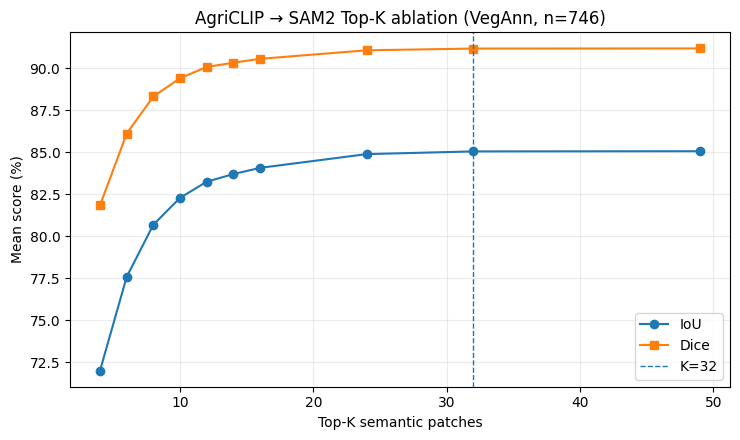

In [29]:
# Optional figure for thesis (no alteration of table values).
plt.figure(figsize=(7.5,4.5))
plt.plot(summary['K'], summary['iou_%'], marker='o', label='IoU')
plt.plot(summary['K'], summary['dice_%'], marker='s', label='Dice')
plt.axvline(32, linestyle='--', linewidth=1, label='K=32')
plt.xlabel('Top-K semantic patches')
plt.ylabel('Mean score (%)')
plt.title('AgriCLIP → SAM2 Top-K ablation (VegAnn, n=746)')
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'topk_ablation_746.png', dpi=220)
plt.show()


In [30]:
import pandas as pd
from IPython.display import display

# Load results generated by the Top-K ablation notebook
csv_path = "/home/zahranadeem/thesis/final_topk_ablation_746/topk_ablation_746_summary.csv"

df = pd.read_csv(csv_path)

print("=" * 75)
print("Top-K Semantic Patch Ablation — AgriCLIP + SAM2")
print("Dataset: VegAnn | Non-empty images: 746")
print("=" * 75)

# Display available columns to confirm their names
print("CSV columns:", df.columns.tolist())

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Rename common column variations
df = df.rename(columns={
    "k": "K",
    "mean_iou": "IoU (%)",
    "mean_dice": "Dice (%)",
    "mean_precision": "Precision (%)",
    "mean_recall": "Recall (%)",
    "iou": "IoU (%)",
    "dice": "Dice (%)",
    "precision": "Precision (%)",
    "recall": "Recall (%)"
})

cols = ["K", "IoU (%)", "Dice (%)", "Precision (%)", "Recall (%)"]
table = df[cols].copy()

# Convert fractions (0–1) to percentages when needed
for col in cols[1:]:
    table[col] = pd.to_numeric(table[col])
    if table[col].max() <= 1:
        table[col] *= 100

table = table.sort_values("K")

display(table.style.format({
    "IoU (%)": "{:.2f}",
    "Dice (%)": "{:.2f}",
    "Precision (%)": "{:.2f}",
    "Recall (%)": "{:.2f}"
}).highlight_max(subset=["IoU (%)"], color="#d8f3dc"))

print("\nFINAL ABLATION TABLE:\n")
print(table.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Verify K=32
k32 = table[table["K"] == 32]

if not k32.empty:
    iou32 = k32["IoU (%)"].iloc[0]
    print(f"\nK=32 IoU: {iou32:.2f}%")
    print(f"Difference from previous 746-image result (85.04%): {iou32 - 85.04:+.2f} pp")

Top-K Semantic Patch Ablation — AgriCLIP + SAM2
Dataset: VegAnn | Non-empty images: 746
CSV columns: ['K', 'n', 'iou_%', 'dice_%', 'precision_%', 'recall_%']


KeyError: "['IoU (%)', 'Dice (%)', 'Precision (%)', 'Recall (%)'] not in index"